# ПР №2 — Разведочный анализ данных (EDA), уровень B

Преподавательский датасет **не прикреплён**. В этой воспроизводимой демонстрации используется `data/dirty_employees.csv`: **искусственный учебный набор**, содержащий пропуски, выбросы и редкие категории. Его нельзя выдавать за реальные данные преподавателя.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
DATA=Path('../data/dirty_employees.csv'); FIG=Path('../figures'); FIG.mkdir(exist_ok=True)
df=pd.read_csv(DATA)
num=df.select_dtypes(include='number').columns.drop('will_leave').tolist()
cat=df.select_dtypes(exclude='number').columns.tolist()
print('Размер:',df.shape)
print('Числовые:',num,'\nКатегориальные:',cat,'\nЦелевая: will_leave (0/1)')
display(pd.DataFrame({'dtype':df.dtypes.astype(str),'missing':df.isna().sum(),'missing_%':(100*df.isna().mean()).round(1)}))
display(df.describe(include='all'))

Размер: (480, 7)
Числовые: ['age', 'experience_years', 'monthly_income_som', 'household_size'] 
Категориальные: ['city', 'contract_type'] 
Целевая: will_leave (0/1)


,dtype,missing,missing_%
age,float64,24,5.0
experience_years,float64,28,5.8
monthly_income_som,float64,42,8.8
household_size,float64,16,3.3
city,object,21,4.4
contract_type,object,26,5.4
will_leave,int64,0,0.0


,age,experience_years,monthly_income_som,household_size,city,contract_type,will_leave
count,456.000000,452.000000,4.380000e+02,464.000000,459,454,480.000000
unique,NaN,NaN,NaN,NaN,6,4,NaN
top,NaN,NaN,NaN,NaN,Бишкек,постоянный,NaN
freq,NaN,NaN,NaN,NaN,241,314,NaN
mean,39.493288,14.586283,6.506752e+04,4.122845,NaN,NaN,0.231250
std,13.362036,11.489862,7.512699e+04,1.994592,NaN,NaN,0.422072
min,19.000000,0.000000,1.407565e+04,1.000000,NaN,NaN,0.000000
25%,30.000000,4.000000,3.958422e+04,2.000000,NaN,NaN,0.000000
50%,38.000000,14.000000,5.313765e+04,4.000000,NaN,NaN,0.000000
75%,49.000000,24.000000,7.267030e+04,6.000000,NaN,NaN,0.000000


## Числовые признаки: распределения и выбросы

Для каждой количественной переменной строим гистограмму и boxplot; критерий выбросов — за пределами `Q1−1.5×IQR` и `Q3+1.5×IQR`. Это лишь **кандидаты** в выбросы, не автоматическое удаление.

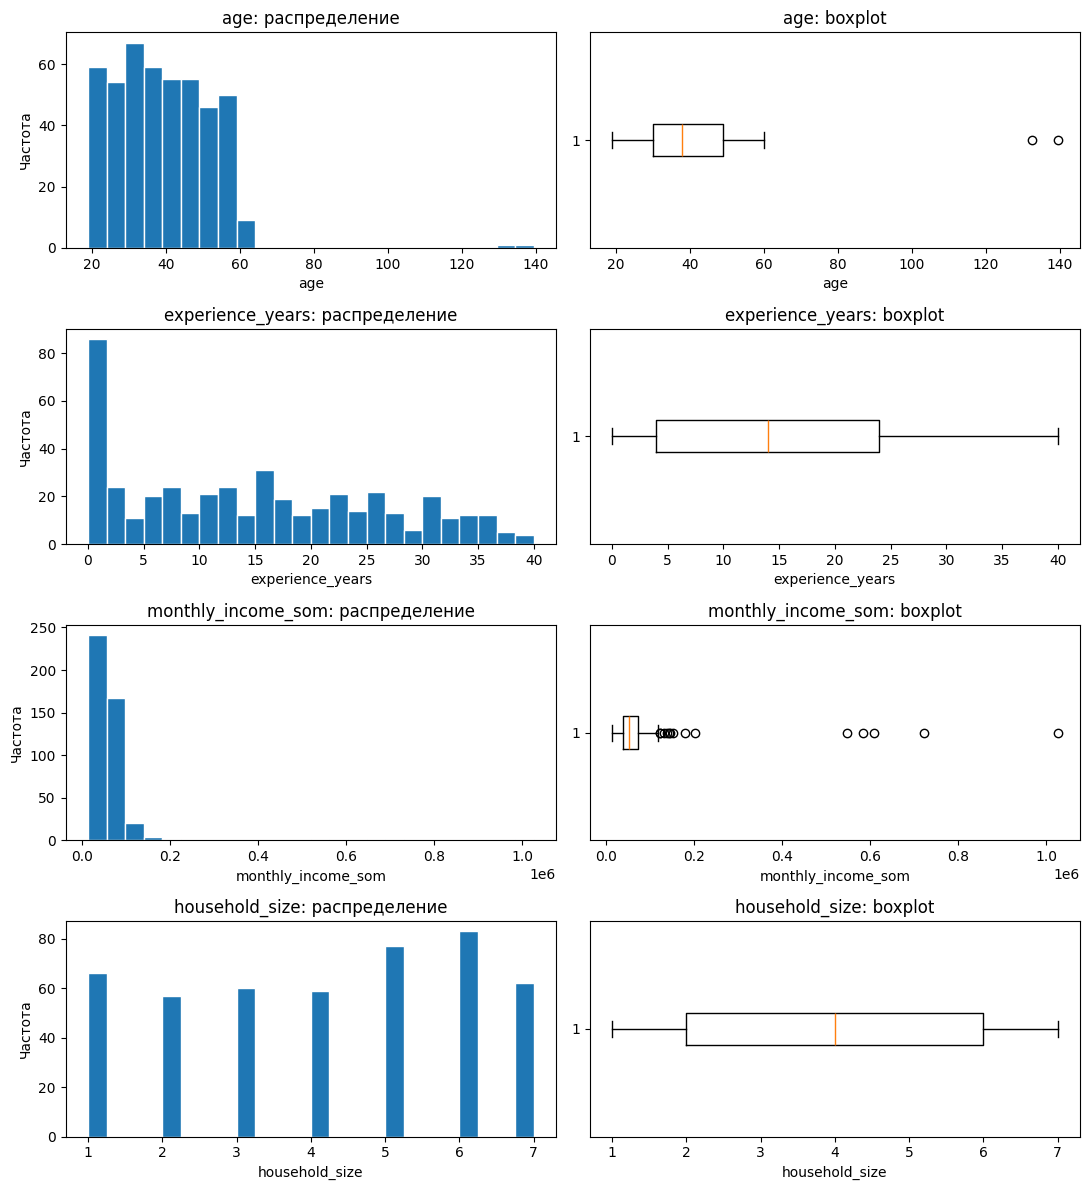

,Признак,Кандидаты в выбросы,% от ненулевых
0,age,2,0.4
1,experience_years,0,0.0
2,monthly_income_som,14,3.2
3,household_size,0,0.0


In [2]:
fig,axs=plt.subplots(len(num),2,figsize=(11,3*len(num)))
for k,col in enumerate(num):
    vals=df[col].dropna()
    axs[k,0].hist(vals,bins=24,edgecolor='white');axs[k,0].set(title=f'{col}: распределение',xlabel=col,ylabel='Частота')
    axs[k,1].boxplot(vals,vert=False);axs[k,1].set(title=f'{col}: boxplot',xlabel=col)
fig.tight_layout();fig.savefig(FIG/'numerical_distributions.png',dpi=110);plt.show()
issues=[]
for col in num:
    s=df[col].dropna();q1,q3=s.quantile([.25,.75]);iqr=q3-q1
    cnt=((s<q1-1.5*iqr)|(s>q3+1.5*iqr)).sum()
    issues.append([col,int(cnt),round(cnt/len(s)*100,1)])
display(pd.DataFrame(issues,columns=['Признак','Кандидаты в выбросы','% от ненулевых']))

## Категории и редкие значения

Редкими для этой работы считаем категории с частотой менее **5%** от всех непустых значений.


 city 
 city
Бишкек     241
Ош          91
Нарын       43
Каракол     43
Талас       33
NaN         21
Баткен       8
Редкие значения (<5%): ['Баткен']

 contract_type 
 contract_type
постоянный             314
временный               82
частичная занятость     42
NaN                     26
фриланс                 16
Редкие значения (<5%): ['фриланс']


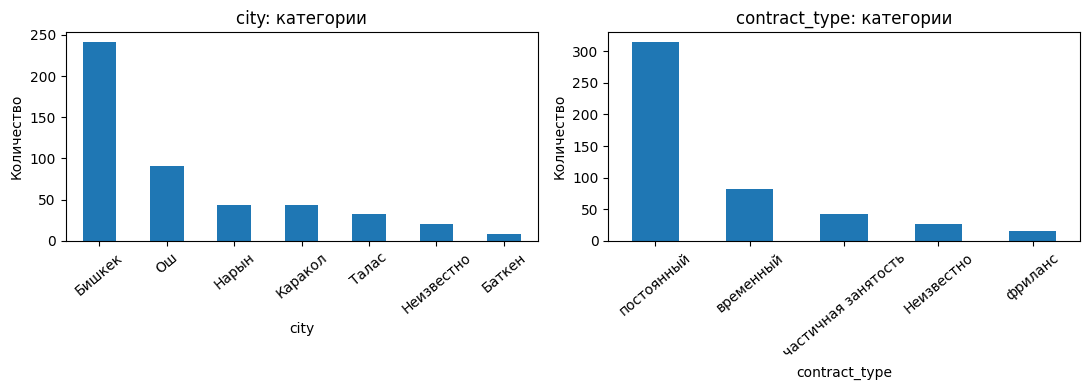

In [3]:
for col in cat:
    vc=df[col].value_counts(dropna=False)
    print('\n',col,'\n',vc.to_string())
    rare=df[col].value_counts(normalize=True).loc[lambda x:x<.05].index.tolist()
    print('Редкие значения (<5%):',rare)
fig,axs=plt.subplots(1,len(cat),figsize=(11,4))
for ax,col in zip(axs,cat):
    df[col].fillna('Неизвестно').value_counts().plot(kind='bar',ax=ax)
    ax.set(title=f'{col}: категории',xlabel=col,ylabel='Количество');ax.tick_params(axis='x',labelrotation=40)
fig.tight_layout();fig.savefig(FIG/'categories.png',dpi=120);plt.show()

## Корреляция и наиболее связанные пары

В матрицу включаем только **числовые входные признаки**; бинарную целевую переменную анализируем отдельно. Корреляция не доказывает причинность.

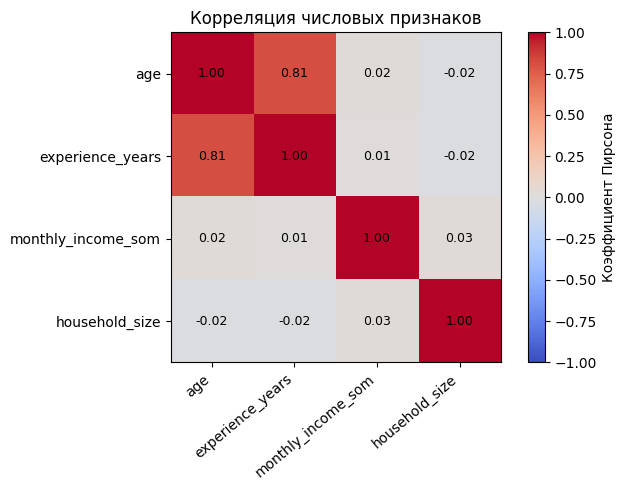

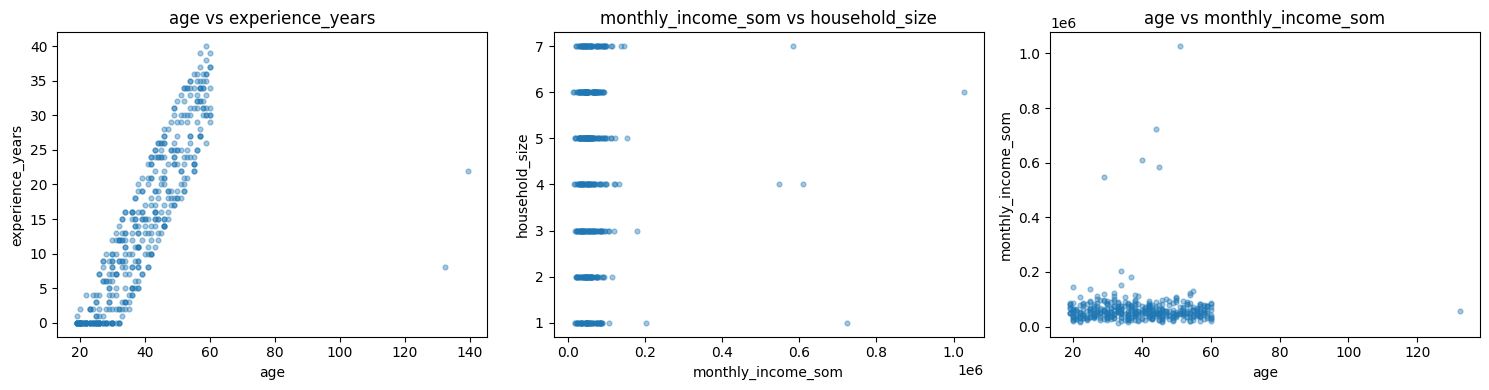

Топ-пары: [('age', 'experience_years', np.float64(0.806)), ('monthly_income_som', 'household_size', np.float64(0.029)), ('age', 'monthly_income_som', np.float64(0.025))]


In [4]:
corr=df[num].corr()
fig,ax=plt.subplots(figsize=(7,5));im=ax.imshow(corr,vmin=-1,vmax=1,cmap='coolwarm')
ax.set_xticks(range(len(num)),num,rotation=40,ha='right');ax.set_yticks(range(len(num)),num)
for i in range(len(num)):
    for j in range(len(num)):ax.text(j,i,f'{corr.iloc[i,j]:.2f}',ha='center',va='center',fontsize=9)
fig.colorbar(im,ax=ax,label='Коэффициент Пирсона')
ax.set_title('Корреляция числовых признаков')
fig.tight_layout();fig.savefig(FIG/'correlation.png',dpi=130);plt.show()
pairs=[(abs(corr.loc[a,b]),a,b) for i,a in enumerate(num) for b in num[i+1:]]
pairs=sorted(pairs,reverse=True)[:3]
fig,axs=plt.subplots(1,len(pairs),figsize=(5*len(pairs),4))
for ax,(_,a,b) in zip(np.atleast_1d(axs),pairs):
    ax.scatter(df[a],df[b],alpha=.4,s=12);ax.set(title=f'{a} vs {b}',xlabel=a,ylabel=b)
fig.tight_layout();fig.savefig(FIG/'top_scatter_pairs.png',dpi=110);plt.show()
print('Топ-пары:',[(a,b,round(score,3)) for score,a,b in pairs])

## Дисбаланс целевой переменной

Доли классов: {0: 0.769, 1: 0.231}


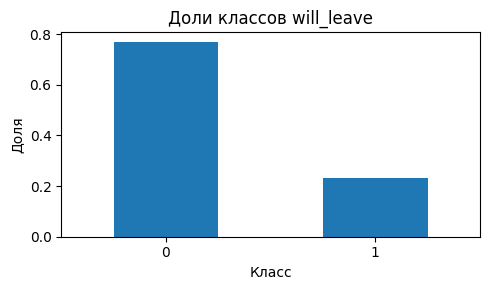

In [5]:
counts=df['will_leave'].value_counts(normalize=True).sort_index()
print('Доли классов:',counts.round(3).to_dict())
fig,ax=plt.subplots(figsize=(5,3));counts.plot.bar(ax=ax,rot=0);ax.set(title='Доли классов will_leave',xlabel='Класс',ylabel='Доля')
fig.tight_layout();fig.savefig(FIG/'target_balance.png',dpi=125);plt.show()

## Отчёт: проблемы и план решения (6 пунктов)

1. **Пропуски в числовых столбцах.** Проверены по столбцам; на следующем занятии заполним на `train` медианами, чтобы тест не влиял на оценки.
2. **Пропуски в категориях.** Превратим в явную категорию `Неизвестно`, а затем применим one-hot.
3. **Сильно завышенные доходы.** Boxplot и IQR обнаруживают аномалии; проверим их происхождение и влияние на модель, не будем удалять механически.
4. **Нереалистичный возраст.** В учебном наборе встречаются аномальные значения; в реальном проекте их надо перепроверить по первоисточнику.
5. **Редкие город/тип договора.** OneHotEncoder с `handle_unknown='ignore'` сохранит одинаковое число признаков на train/test; объединение редких категорий возможно при необходимости.
6. **Корреляция и классы.** Некоторые входные признаки связаны; проверим влияние на модель. Целевой класс менее распространён — разбиение делаем со `stratify`.

Все решения по заполнению и масштабированию будут подбираться **после разбиения** на train и test.